# 03 — Apprendimento: CNN 1D sulla serie grezza e modelli sulle feature

**Compito.** Stimare $H$ da una traiettoria di fBm (stesso dataset dei notebook 01–02).

**Approcci di questo notebook**

| # | Modello | Input |
|---|---|---|
| 3 | **CNN 1D** (modello principale) | serie grezza degli incrementi (fGn), normalizzata |
| 3-MLP | Percettrone multistrato (baseline neurale semplice) | feature riassuntive |
| 3-GBT | Alberi di decisione con gradient boosting (visti nel corso) | feature riassuntive |

Le feature riassuntive sono quelle calcolate nel notebook 02, in tre gruppi:
**classiche** (stime DFA e R/S e le curve $\log F(s)$, $\log\langle R/S\rangle(n)$ su 12 scale: 26 numeri),
**grafo** (16 feature dei grafi di visibilità), **tutte** (42).

I modelli sulle feature formano la cella "senza serie grezza, con feature fisiche" del disegno 2×2 (D-12);
la CNN è la cella "con serie grezza, senza feature fisiche". La cella mista (ibrido) è nel notebook 05.

**Protocollo comune (stesso sforzo di tuning per tutti, D-27):** per ogni modello due configurazioni di
iperparametri, scelta sul **validation**; poi la configurazione scelta è riaddestrata con più seed
(ensemble, D-11). Il **test** si usa solo alla fine.

**Contenuto:** 1. Configurazione · 2. Normalizzazione degli input · 3. CNN · 4. Modelli sulle feature ·
5. Confronto sul test · 6. Incertezza dell'ensemble · 7. Robustezza rispetto a $N$ · 8. Salvataggio · 9. Riepilogo

In [1]:
# --- Setup: su Colab clona il repository; ovunque installa ciò che manca ---
import os, sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Arminas00/stochastic-ml.git"
if IN_COLAB:
    repo = "/content/stochastic-ml"
    if os.path.exists(repo):
        subprocess.run(["git", "-C", repo, "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo], check=True)
    os.chdir(repo)

needed = ["numpy", "scipy", "pandas", "matplotlib", "sklearn", "ts2vg", "torch"]
missing = [m for m in needed if importlib.util.find_spec(m) is None]
if missing:
    print("Installo:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
print("Cartella di lavoro:", os.getcwd(), "| Colab:", IN_COLAB)

Cartella di lavoro: C:\Users\user\Downloads\AI_Project\stochastic-ml | Colab: False


## 1. Configurazione

In modalità `quick` (CPU) le reti sono più piccole, con meno epoche e 3 seed invece di 5: serve a verificare
che tutto giri (~15–20 minuti su un portatile senza GPU). I numeri definitivi sono quelli della modalità
`full` su GPU.

In [2]:
MODE = "quick"          # deve coincidere con i notebook 01-02
SEED = 2026
DATA_DIR = "data"
FIG_DIR = "figures"
N_BOOT = 1000

if MODE == "quick":
    N_SEEDS = 3
    CNN_GRID = [dict(width=8), dict(width=16)]
    TRAIN_KW = dict(max_epochs=15, patience=5, batch_size=128, lr=2e-3)
else:
    N_SEEDS = 5
    CNN_GRID = [dict(width=16), dict(width=32)]
    TRAIN_KW = dict(max_epochs=40, patience=6, batch_size=128, lr=1e-3)

MLP_GRID = [dict(hidden=64, n_layers=2), dict(hidden=128, n_layers=3)]
MLP_TRAIN_KW = dict(max_epochs=200, patience=15, batch_size=128, lr=1e-3)
GBT_GRID = [dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=15),
            dict(max_iter=600, learning_rate=0.05, max_leaf_nodes=31)]

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.ensemble import HistGradientBoostingRegressor

import sp_utils as u

u.set_seed(SEED)
Path(FIG_DIR).mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def savefig(name):
    plt.savefig(f"{FIG_DIR}/03_{name}.png", bbox_inches="tight", dpi=150)

DEV = u.get_device()
print("Dispositivo:", DEV, "| torch", torch.__version__)

CFG = u.MODES[MODE]
ds = u.load_or_make_fbm_dataset(MODE, SEED, DATA_DIR)
feats = u.load_or_make_features(ds, MODE, SEED, DATA_DIR)
SPLITS = list(ds)
H = {s: ds[s]["H"].astype(np.float64) for s in SPLITS}
TIMES = {}   # tempo di addestramento per modello (per la discussione sul costo)

Dispositivo: cpu | torch 2.15.0+cpu


## 2. Normalizzazione degli input della CNN

Nel notebook 01 abbiamo visto che la varianza campionaria di una serie vale in media $1-N^{2H-2}$: dipende da
$H$. Ci sono due scelte possibili (D-19):

- **per serie**: ogni serie a media 0 e deviazione standard 1. Toglie l'ampiezza, che per stimare $H$ (un
  esponente invariante di scala) non dovrebbe servire, ma toglie anche quell'indizio statistico;
- **globale**: si divide tutto per un'unica scala calcolata sul train. Conserva l'ampiezza.

C'è un punto fisico importante: nelle nostre simulazioni il fGn ha **sempre varianza 1**, quindi con la
normalizzazione globale la rete può usare la varianza della serie come indizio di $H$. Su dati reali
l'ampiezza è arbitraria (dipende dall'unità di misura, dalla volatilità del periodo...), e questo indizio non
esiste: sarebbe un **artefatto della simulazione**. Proviamo comunque entrambe, per misurare quanto vale.

In [4]:
train_scale = float(ds["train"]["X"].std())
XN = {how: {s: u.normalize_series(ds[s]["X"], how, train_scale) for s in SPLITS}
      for how in ["per_serie", "globale"]}
print(f"Scala globale (deviazione standard del train): {train_scale:.4f}")

Scala globale (deviazione standard del train): 0.9989


## 3. CNN 1D sulla serie grezza

**Architettura** (`sp_utils.CNN1D`): 4 blocchi [Conv1d(k=7) → BatchNorm → ReLU → Conv1d(k=7) → BatchNorm → ReLU →
MaxPool(2)], con larghezza dei canali che raddoppia fino a 4× la base; poi **pooling globale** (media e massimo
sul tempo) e una testa densa 64 → 1. Il campo recettivo dell'ultimo blocco copre ~200 punti, cioè le scale su
cui DFA e R/S misurano la legge di potenza. Il pooling globale rende la rete indipendente dalla lunghezza $N$
(serve per le prove di robustezza). Motivazioni e alternative in D-25.

**Addestramento** (`sp_utils.train_regressor`): perdita MSE sul target standardizzato, Adam, learning rate
dimezzato se la validazione non migliora per 3 epoche, early stopping sulla validazione con ripristino dei pesi
migliori.

In [5]:
def fit_cnn(how, hp, seed, verbose=False):
    m = u.build_model("cnn", **hp)
    return u.train_regressor(m, XN[how]["train"], H["train"], XN[how]["val"], H["val"],
                             seed=seed, verbose=verbose, **TRAIN_KW)

search_rows, best_hp, hist0 = [], {}, {}
for how in ["per_serie", "globale"]:
    for hp in CNN_GRID:
        t0 = time.time()
        m, hist = fit_cnn(how, hp, seed=SEED)
        val = min(h["rmse_val"] for h in hist)
        search_rows.append({"normalizzazione": how, **hp, "parametri": u.count_params(m),
                            "epoche": len(hist), "RMSE val": val, "secondi": time.time() - t0})
        if how not in best_hp or val < best_hp[how][1]:
            best_hp[how] = (hp, val); hist0[how] = hist
df_search = pd.DataFrame(search_rows); display(df_search.round(4))
print("Configurazione scelta (validation):", {k: v[0] for k, v in best_hp.items()})

,normalizzazione,width,parametri,epoche,RMSE val,secondi
0,per_serie,8,33033,15,0.0361,43.4980
1,per_serie,16,122385,8,0.0387,49.5962
2,globale,8,33033,14,0.0310,36.8897
3,globale,16,122385,7,0.0352,43.6557


Configurazione scelta (validation): {'per_serie': {'width': 8}, 'globale': {'width': 8}}


**Ensemble.** La configurazione scelta viene addestrata con `N_SEEDS` seed diversi (inizializzazione e
ordine dei batch). La previsione è la media dell'ensemble; la deviazione standard tra i membri è un'incertezza
per singola serie. Riportiamo anche la dispersione dell'RMSE tra i singoli membri (variabilità tra run).

In [6]:
PRED, PRED_STD, MEMBER_RMSE = {}, {}, {}
CNN_MODELS = {}
for how in ["per_serie", "globale"]:
    hp = best_hp[how][0]
    t0 = time.time()
    members = [fit_cnn(how, hp, seed=SEED + 100 * k)[0] for k in range(N_SEEDS)]
    TIMES[f"3 CNN ({how})"] = time.time() - t0
    CNN_MODELS[how] = members
    P = {s: np.stack([u.predict(m, XN[how][s]) for m in members]) for s in SPLITS}
    name = f"3 CNN ({how})"
    PRED[name] = {s: P[s].mean(0) for s in SPLITS}
    PRED_STD[name] = {s: P[s].std(0) for s in SPLITS}
    MEMBER_RMSE[name] = [u.regression_metrics(H["val"], P["val"][k])["RMSE"] for k in range(N_SEEDS)]
    print(f"{name}: RMSE validation dei membri = {np.round(MEMBER_RMSE[name], 4)}, "
          f"ensemble = {u.regression_metrics(H['val'], PRED[name]['val'])['RMSE']:.4f}  ({TIMES[name]:.0f} s)")

3 CNN (per_serie): RMSE validation dei membri = [0.0332 0.0357 0.0309], ensemble = 0.0306  (116 s)


3 CNN (globale): RMSE validation dei membri = [0.0294 0.0334 0.0323], ensemble = 0.0276  (103 s)


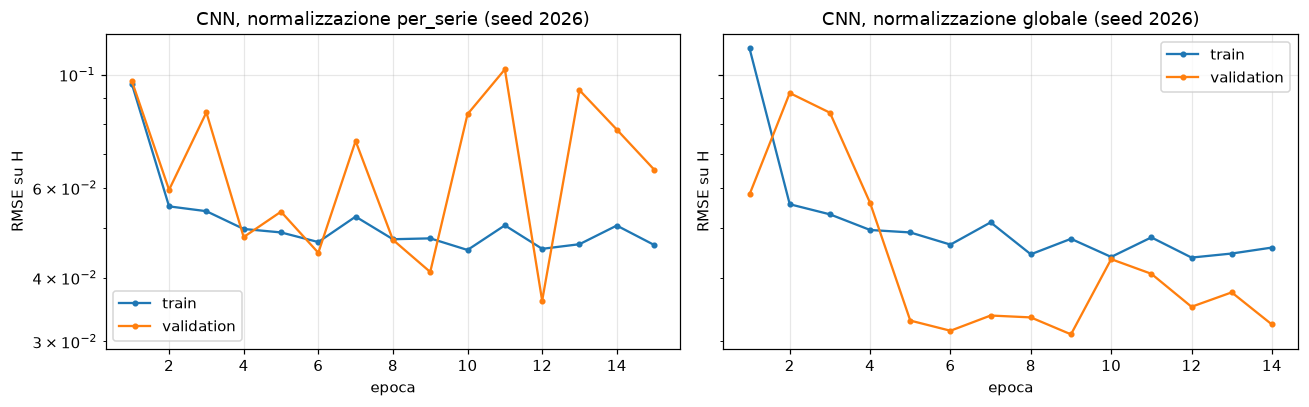

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, how in zip(axes, ["per_serie", "globale"]):
    h = pd.DataFrame(hist0[how])
    ax.plot(h["epoch"], h["rmse_train"], "o-", ms=3, label="train")
    ax.plot(h["epoch"], h["rmse_val"], "o-", ms=3, label="validation")
    ax.set(title=f"CNN, normalizzazione {how} (seed {SEED})", xlabel="epoca", ylabel="RMSE su H", yscale="log")
    ax.legend()
plt.tight_layout(); savefig("curve_apprendimento"); plt.show()

## 4. Modelli sulle feature riassuntive

Feature standardizzate con media e deviazione del **train** (valori mancanti → mediana del train).
Due modelli, con lo stesso protocollo: **MLP** (rete densa, ensemble di `N_SEEDS` seed) e
**gradient boosting** (`HistGradientBoostingRegressor` di scikit-learn, deterministico: un solo modello).

In [8]:
def feature_matrix(f, group):
    classic = np.column_stack([f["dfa"], f["rs"], f["logF"], f["logRS"]])
    if group == "classiche":
        return classic
    if group == "grafo":
        return f["graph"]
    return np.column_stack([classic, f["graph"]])

FSETS = {}
for group in ["classiche", "grafo", "tutte"]:
    raw = {s: feature_matrix(feats[s], group) for s in SPLITS}
    sc = u.FeatureScaler().fit(raw["train"])
    FSETS[group] = {s: sc.transform(raw[s]) for s in SPLITS}
    print(f"{group:<10}: {FSETS[group]['train'].shape[1]} feature")

classiche : 26 feature
grafo     : 16 feature
tutte     : 42 feature


In [9]:
feat_rows = []
for group, F in FSETS.items():
    # --- MLP: scelta della configurazione sul validation (seed fisso), poi ensemble ---
    best = None
    for hp in MLP_GRID:
        m, hist = u.train_regressor(u.build_model("mlp", n_in=F["train"].shape[1], **hp),
                                    F["train"], H["train"], F["val"], H["val"], seed=SEED, **MLP_TRAIN_KW)
        val = min(h["rmse_val"] for h in hist)
        feat_rows.append({"modello": "MLP", "feature": group, **hp, "RMSE val": val})
        if best is None or val < best[1]:
            best = (hp, val)
    t0 = time.time()
    members = [u.train_regressor(u.build_model("mlp", n_in=F["train"].shape[1], **best[0]),
                                 F["train"], H["train"], F["val"], H["val"], seed=SEED + 100 * k, **MLP_TRAIN_KW)[0]
               for k in range(N_SEEDS)]
    name = f"3-MLP feature {group}"
    TIMES[name] = time.time() - t0
    P = {s: np.stack([u.predict(m, F[s]) for m in members]) for s in SPLITS}
    PRED[name] = {s: P[s].mean(0) for s in SPLITS}
    PRED_STD[name] = {s: P[s].std(0) for s in SPLITS}
    MEMBER_RMSE[name] = [u.regression_metrics(H["val"], P["val"][k])["RMSE"] for k in range(N_SEEDS)]

    # --- Gradient boosting ---
    best = None
    for hp in GBT_GRID:
        g = HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **hp).fit(F["train"], H["train"])
        val = u.regression_metrics(H["val"], g.predict(F["val"]))["RMSE"]
        feat_rows.append({"modello": "GBT", "feature": group, **hp, "RMSE val": val})
        if best is None or val < best[1]:
            best = (hp, val, g)
    name = f"3-GBT feature {group}"
    PRED[name] = {s: best[2].predict(F[s]) for s in SPLITS}

df_feat = pd.DataFrame(feat_rows)
display(df_feat.round(4))

,modello,feature,hidden,n_layers,RMSE val,max_iter,learning_rate,max_leaf_nodes
0,MLP,classiche,64.0,2.0,0.0297,NaN,NaN,NaN
1,MLP,classiche,128.0,3.0,0.0297,NaN,NaN,NaN
2,GBT,classiche,NaN,NaN,0.0291,300.0,0.05,15.0
3,GBT,classiche,NaN,NaN,0.0295,600.0,0.05,31.0
4,MLP,grafo,64.0,2.0,0.0397,NaN,NaN,NaN
5,MLP,grafo,128.0,3.0,0.0398,NaN,NaN,NaN
6,GBT,grafo,NaN,NaN,0.0370,300.0,0.05,15.0
7,GBT,grafo,NaN,NaN,0.0377,600.0,0.05,31.0
8,MLP,tutte,64.0,2.0,0.0271,NaN,NaN,NaN
9,MLP,tutte,128.0,3.0,0.0271,NaN,NaN,NaN


## 5. Confronto sul test set

Aggiungiamo i riferimenti del notebook 02 (stesso test set): baseline banale e DFA grezza.

In [10]:
p02 = np.load(Path(DATA_DIR) / f"preds02_{MODE}_seed{SEED}.npz")
for ref in ["0 baseline (media)", "1a DFA"]:
    PRED[ref] = {s: p02[f"{ref}__{s}"] for s in SPLITS}

order = ["0 baseline (media)", "1a DFA", "3 CNN (per_serie)", "3 CNN (globale)",
         "3-MLP feature classiche", "3-GBT feature classiche", "3-MLP feature grafo", "3-GBT feature grafo",
         "3-MLP feature tutte", "3-GBT feature tutte"]
rows = []
for name in order:
    m = u.regression_metrics(H["test"], PRED[name]["test"])
    lo, hi = u.bootstrap_ci(H["test"], PRED[name]["test"], "RMSE", n_boot=N_BOOT, seed=SEED)
    rows.append({"metodo": name, "RMSE": m["RMSE"], "IC 95% RMSE": f"[{lo:.3f}, {hi:.3f}]", "MAE": m["MAE"],
                 "bias": m["bias"], "R2": m["R2"], "std previsioni": m["std previsioni"],
                 "RMSE val membri (media ± std)": (f"{np.mean(MEMBER_RMSE[name]):.4f} ± {np.std(MEMBER_RMSE[name]):.4f}"
                                                   if name in MEMBER_RMSE else "")})
df_res = pd.DataFrame(rows).set_index("metodo")
display(df_res.round(4))

,RMSE,IC 95% RMSE,MAE,bias,R2,std previsioni,RMSE val membri (media ± std)
metodo,,,,,,,
0 baseline (media),0.2591,"[0.254, 0.264]",0.2234,0.0001,-0.0000,0.0000,
1a DFA,0.0533,"[0.051, 0.055]",0.0414,0.0049,0.9577,0.2524,
3 CNN (per_serie),0.0308,"[0.030, 0.032]",0.0244,-0.0055,0.9858,0.2602,0.0333 ± 0.0020
3 CNN (globale),0.0285,"[0.028, 0.029]",0.0224,0.0015,0.9879,0.2639,0.0317 ± 0.0017
3-MLP feature classiche,0.0281,"[0.027, 0.029]",0.0222,-0.0001,0.9882,0.2566,0.0295 ± 0.0001
3-GBT feature classiche,0.0274,"[0.026, 0.028]",0.0210,-0.0005,0.9888,0.2583,
3-MLP feature grafo,0.0397,"[0.038, 0.041]",0.0312,-0.0005,0.9765,0.2536,0.0396 ± 0.0003
3-GBT feature grafo,0.0369,"[0.036, 0.038]",0.0293,-0.0003,0.9797,0.2553,
3-MLP feature tutte,0.0266,"[0.026, 0.027]",0.0210,-0.0008,0.9895,0.2551,0.0275 ± 0.0005


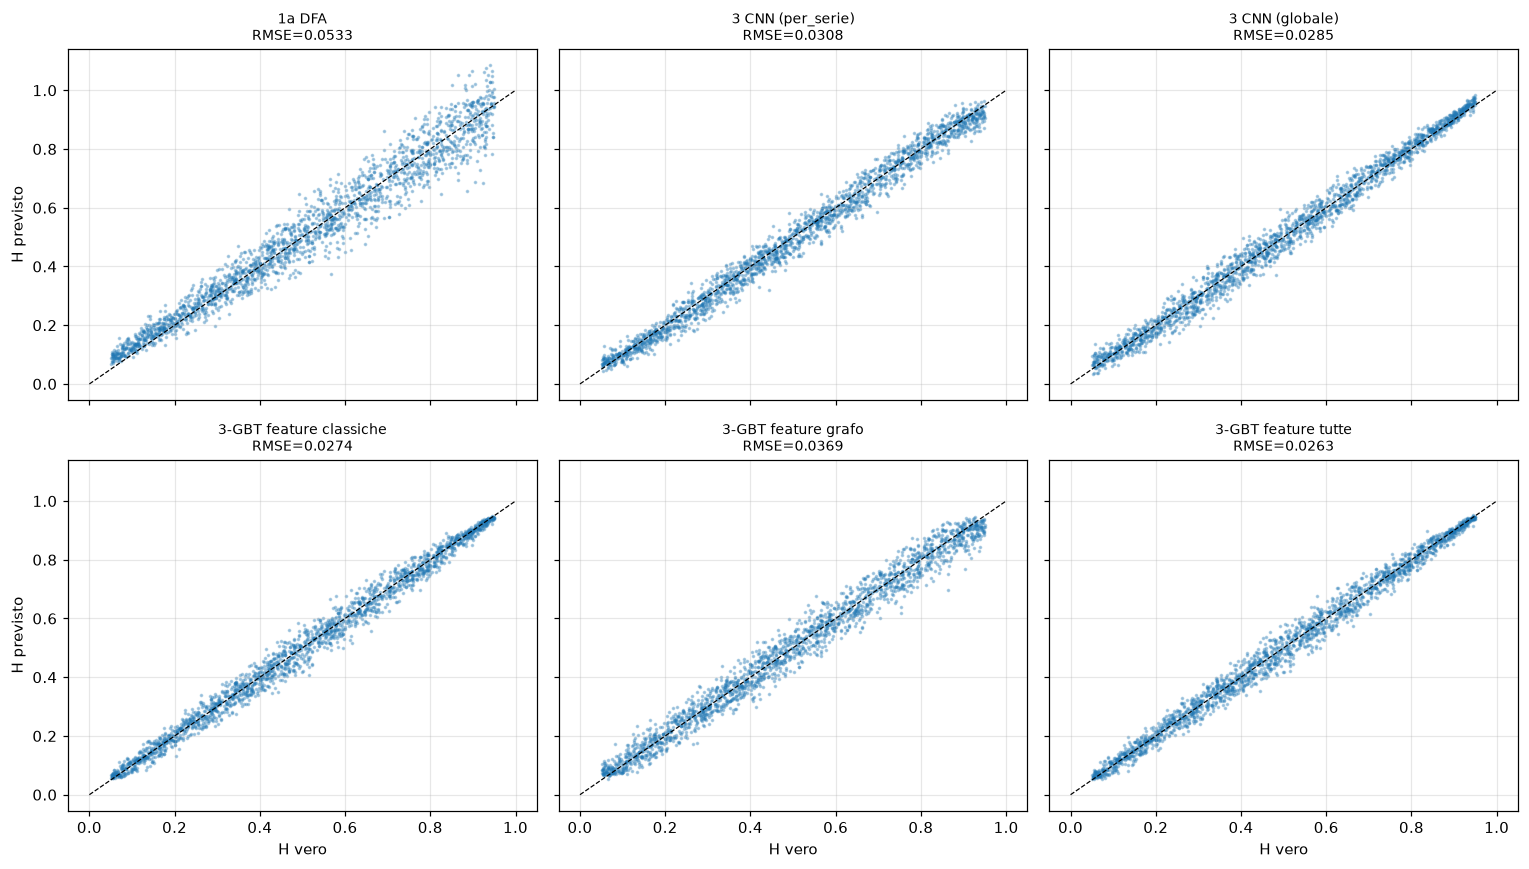

In [11]:
show = ["1a DFA", "3 CNN (per_serie)", "3 CNN (globale)", "3-GBT feature classiche", "3-GBT feature grafo", "3-GBT feature tutte"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, show):
    ax.scatter(H["test"], PRED[name]["test"], s=2, alpha=0.3)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{name}\nRMSE={df_res.loc[name, 'RMSE']:.4f}", fontsize=9)
for ax in axes[-1]: ax.set_xlabel("H vero")
for ax in axes[:, 0]: ax.set_ylabel("H previsto")
plt.tight_layout(); savefig("scatter"); plt.show()

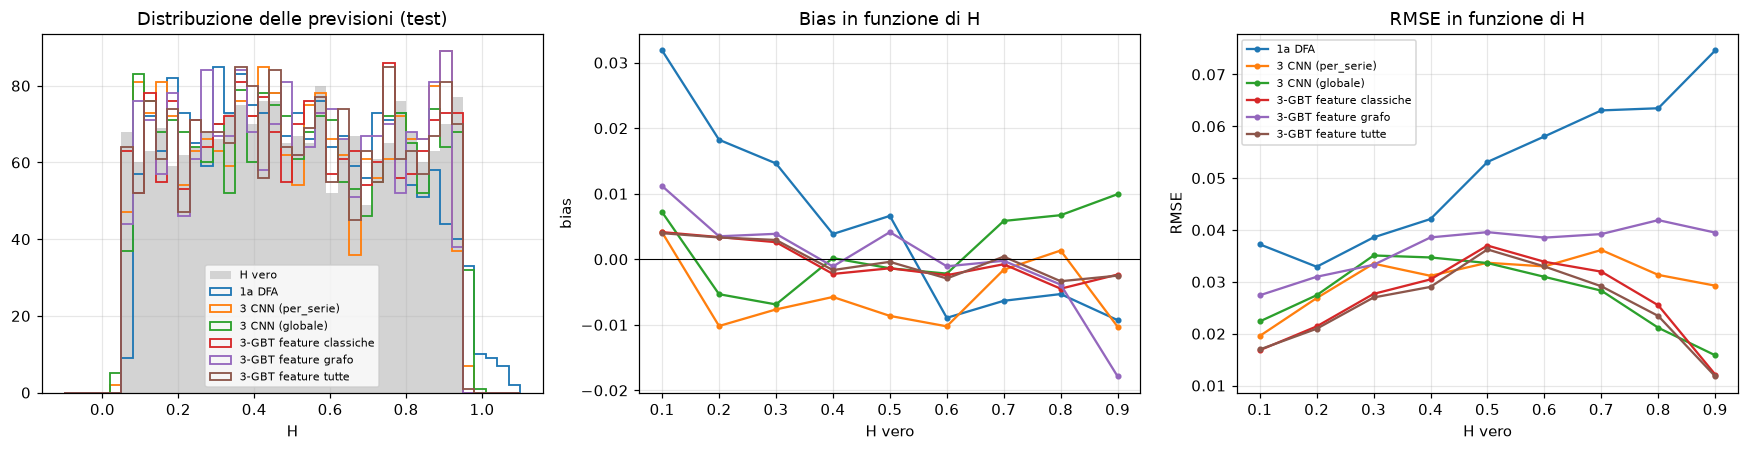

In [12]:
bins = np.linspace(0.05, 0.95, 10)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(H["test"], bins=40, range=(-0.1, 1.1), histtype="stepfilled", color="lightgrey", label="H vero")
for name in show:
    axes[0].hist(PRED[name]["test"], bins=40, range=(-0.1, 1.1), histtype="step", lw=1.2, label=name)
    be = u.binned_errors(H["test"], PRED[name]["test"], bins)
    axes[1].plot(be["centers"], be["bias"], "o-", ms=3, label=name)
    axes[2].plot(be["centers"], be["rmse"], "o-", ms=3, label=name)
axes[0].set(xlabel="H", title="Distribuzione delle previsioni (test)"); axes[0].legend(fontsize=7)
axes[1].axhline(0, color="k", lw=0.7)
axes[1].set(xlabel="H vero", ylabel="bias", title="Bias in funzione di H")
axes[2].set(xlabel="H vero", ylabel="RMSE", title="RMSE in funzione di H"); axes[2].legend(fontsize=7)
plt.tight_layout(); savefig("errore_vs_H"); plt.show()

## 6. Incertezza dell'ensemble

Se la deviazione standard tra i membri dell'ensemble fosse una buona incertezza, l'errore $|\hat H - H|$
dovrebbe crescere con essa, e l'intervallo $\pm 2\sigma$ dovrebbe contenere il valore vero circa nel 95% dei casi.
Un ensemble di reti cattura solo l'incertezza *del modello* (epistemica), non quella dovuta alla casualità della
singola traiettoria (aleatoria), quindi ci aspettiamo che sottostimi l'errore.

In [13]:
rows = []
for name in PRED_STD:
    err = np.abs(PRED[name]["test"] - H["test"]); sd = PRED_STD[name]["test"]
    rows.append({"metodo": name, "std ensemble media": sd.mean(), "|errore| medio": err.mean(),
                 "copertura ±2σ": np.mean(err <= 2 * sd),
                 "correlazione (σ, |errore|)": np.corrcoef(sd, err)[0, 1]})
display(pd.DataFrame(rows).set_index("metodo").round(3))

,std ensemble media,|errore| medio,copertura ±2σ,"correlazione (σ, |errore|)"
metodo,,,,
3 CNN (per_serie),0.012,0.024,0.526,0.001
3 CNN (globale),0.014,0.022,0.616,0.043
3-MLP feature classiche,0.004,0.022,0.248,-0.045
3-MLP feature grafo,0.005,0.031,0.184,0.051
3-MLP feature tutte,0.004,0.021,0.271,-0.067


## 7. Robustezza rispetto alla lunghezza $N$

La CNN ha pooling globale, quindi accetta serie di qualunque lunghezza; i modelli sulle feature ricevono le
feature calcolate alla nuova lunghezza. Tutti sono stati addestrati solo alla lunghezza del train.

N,128,256,512,1024,2048
metodo,,,,,
1a DFA,0.101,0.072,0.053,0.040,0.034
3 CNN (globale),0.069,0.040,0.028,0.026,0.027
3 CNN (per_serie),0.079,0.048,0.031,0.028,0.031
3-GBT feature classiche,0.287,0.132,0.027,0.094,0.156
3-GBT feature tutte,0.261,0.118,0.026,0.077,0.136
3-MLP feature tutte,0.219,0.090,0.027,0.091,0.172


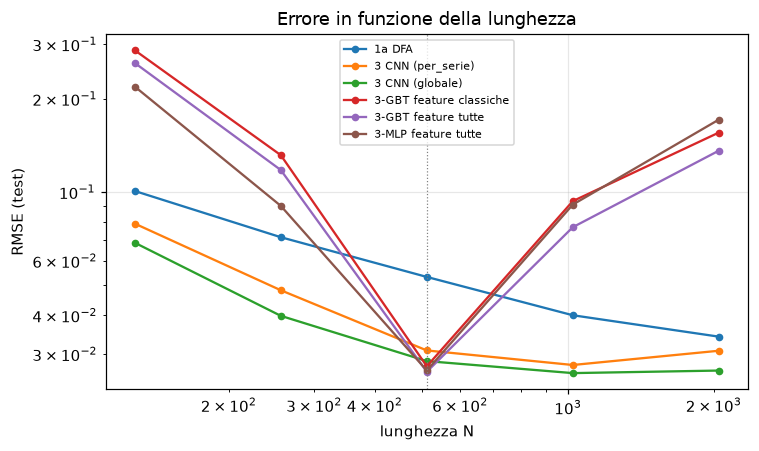

In [14]:
lengths = sorted([CFG["N"]] + list(CFG["robust_lengths"]))
split_of = {L: ("test" if L == CFG["N"] else f"test_N{L}") for L in lengths}
rob = ["1a DFA", "3 CNN (per_serie)", "3 CNN (globale)", "3-GBT feature classiche", "3-GBT feature tutte", "3-MLP feature tutte"]
rows = []
for name in rob:
    for L in lengths:
        s = split_of[L]
        rows.append({"metodo": name, "N": L, "RMSE": u.regression_metrics(H[s], PRED[name][s])["RMSE"]})
df_rob = pd.DataFrame(rows).pivot(index="metodo", columns="N", values="RMSE")
display(df_rob.round(3))
fig, ax = plt.subplots(figsize=(7, 4.2))
for name in rob:
    ax.plot(lengths, df_rob.loc[name, lengths], "o-", ms=4, label=name)
ax.axvline(CFG["N"], color="grey", lw=0.8, ls=":")
ax.set(xscale="log", yscale="log", xlabel="lunghezza N", ylabel="RMSE (test)", title="Errore in funzione della lunghezza")
ax.legend(fontsize=7); plt.tight_layout(); savefig("rmse_vs_N"); plt.show()

## 8. Salvataggio

In [15]:
out = Path(DATA_DIR) / f"preds03_{MODE}_seed{SEED}.npz"
np.savez_compressed(out, **{f"{name}__{s}": v for name, d in PRED.items() for s, v in d.items()},
                    **{f"STD::{name}__{s}": v for name, d in PRED_STD.items() for s, v in d.items()})
df_res.to_csv(Path(DATA_DIR) / f"results03_{MODE}.csv")
torch.save({how: [m.state_dict() for m in ms] for how, ms in CNN_MODELS.items()},
           Path(DATA_DIR) / f"cnn03_{MODE}_seed{SEED}.pt")
print("Salvato", out, "| tempi di addestramento (s):", {k: round(v) for k, v in TIMES.items()})

Salvato data\preds03_quick_seed2026.npz | tempi di addestramento (s): {'3 CNN (per_serie)': 116, '3 CNN (globale)': 103, '3-MLP feature classiche': 8, '3-MLP feature grafo': 13, '3-MLP feature tutte': 12}


## 9. Riepilogo

In [16]:
ref = df_res.loc["1a DFA", "RMSE"]
for name in order[2:]:
    r = df_res.loc[name, "RMSE"]
    print(f"{name:<28} RMSE {r:.4f}   rispetto alla DFA: {100 * (r - ref) / ref:+.0f}%")

3 CNN (per_serie)            RMSE 0.0308   rispetto alla DFA: -42%
3 CNN (globale)              RMSE 0.0285   rispetto alla DFA: -47%
3-MLP feature classiche      RMSE 0.0281   rispetto alla DFA: -47%
3-GBT feature classiche      RMSE 0.0274   rispetto alla DFA: -49%
3-MLP feature grafo          RMSE 0.0397   rispetto alla DFA: -25%
3-GBT feature grafo          RMSE 0.0369   rispetto alla DFA: -31%
3-MLP feature tutte          RMSE 0.0266   rispetto alla DFA: -50%
3-GBT feature tutte          RMSE 0.0263   rispetto alla DFA: -51%


**Cosa mostra questo notebook** (commenti scritti sulla modalità `quick`, con reti piccole e 4000 serie di
train: da ricontrollare sulla `full`)

- **Tutti i modelli appresi battono nettamente la DFA** (RMSE −25%…−50%) e la baseline banale. Gli
  istogrammi delle previsioni seguono la distribuzione uniforme del vero $H$: nessun modello "si rifugia"
  vicino alla media.
- **In quick, i modelli sulle feature classiche valgono quanto o più della CNN.** Il gradient boosting sulle
  curve $\log F(s)$ e $\log\langle R/S\rangle(n)$ ha RMSE ≈ 0.027 contro ≈ 0.031 della CNN (per serie). Una
  piccola rete sulla serie grezza deve *scoprire* la statistica di scala; le curve di DFA e R/S gliela danno
  già pronta. Con più dati ed epoche (modalità full) la distanza può cambiare: è la domanda del notebook 05.
- **Le feature del grafo, usate tutte insieme, contengono molta informazione su $H$**: RMSE ≈ 0.037, il 30%
  meglio della DFA. Il fallimento della relazione di Lacasa (notebook 02) era dunque dovuto alla riduzione
  a un solo esponente, non alla rappresentazione a grafo. Restano però peggiori delle feature classiche.
- **Normalizzazione (D-26):** la CNN con normalizzazione globale è migliore di circa l'8% perché sfrutta la
  varianza della serie, un indizio che esiste solo nelle simulazioni. La CNN principale resta quella
  normalizzata per serie; la differenza misura quanto vale l'artefatto.
- **Attenzione ai bordi del prior.** I modelli appresi hanno l'errore più piccolo vicino a $H=0.05$ e $H=0.95$,
  la DFA no: un modello addestrato su $H\in[0.05,0.95]$ "sa" che non può uscire dall'intervallo e schiaccia
  le previsioni verso l'interno. Parte del vantaggio ai bordi viene quindi dal prior, non dalla fisica; al
  centro dell'intervallo il vantaggio è più piccolo ma resta.
- **Incertezza dell'ensemble: non affidabile.** La dispersione tra i membri copre il valore vero solo nel
  25–60% dei casi con $\pm2\sigma$, ed è scorrelata dall'errore. L'ensemble misura solo l'incertezza del
  modello, non quella della singola traiettoria (che domina). Per incertezze per singola serie servirebbe
  una testa che predice anche la varianza (perdita gaussiana NLL): candidata per il capitolo sui dati reali.
- **Robustezza in lunghezza: la differenza più netta tra le rappresentazioni.** La CNN, grazie al pooling
  globale, funziona su tutte le lunghezze (a $N=2048$ è ancora leggermente meglio della DFA, pur senza
  migliorare come la DFA). I modelli sulle feature crollano appena $N$ cambia (RMSE 0.13–0.29), perché le
  feature dipendono da $N$: le scale della DFA vanno fino a $N/4$, il grado medio del grafo cresce con $N$.
  Un modello sulle feature va addestrato alla lunghezza a cui si usa.

**Decisioni di questo notebook:** D-25 architettura della CNN; D-26 normalizzazione per serie; D-27 stesso
sforzo di tuning; D-28 modelli e gruppi di feature.